**CELDA 0 – Título y configuración general**

In [ ]:
# ============================================================
# Ticki-TI – MVP Modelo de Clasificación de Tickets
# Proyecto APT – Capstone 2026
# ============================================================
# Objetivo: Entrenar modelos para predecir Área de derivación y
#           Prioridad operativa (Binaria).
# Metodología: CRISP-DM
# ============================================================

!pip install -q scikit-learn pandas openpyxl joblib seaborn matplotlib

import pandas as pd
import numpy as np
import re
import joblib
from datetime import datetime

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, f1_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 100)

print("✅ Librerías cargadas correctamente")

✅ Librerías cargadas correctamente


**CELDA 1 – Business Understanding (Fase 1)**

In [ ]:
# ============================================================
# FASE 1: BUSINESS UNDERSTANDING
# ============================================================

print("""
══════════════════════════════════════════════════════════════════
FASE 1 – BUSINESS UNDERSTANDING
══════════════════════════════════════════════════════════════════
Objetivos del presente MVP:
• Construir modelos de Machine Learning capaces de predecir
  el Área de derivación y la Prioridad operativa.
• Ante el solapamiento semántico de las prioridades originales,
  se aplica la cláusula del proyecto de agrupar clases de baja representación:
  - Urgente (Alta / Crítica)
  - Estándar (Media / Baja)
• Alcanzar un F1-macro ≥ 0.65 en ambos modelos cómo criterio de aceptación.
""")


══════════════════════════════════════════════════════════════════
FASE 1 – BUSINESS UNDERSTANDING
══════════════════════════════════════════════════════════════════
Objetivos del presente MVP:
• Construir modelos de Machine Learning capaces de predecir 
  el Área de derivación y la Prioridad operativa.
• Ante el solapamiento semántico de las prioridades originales, 
  se aplica la cláusula del proyecto de agrupar clases de baja representación:
  - Urgente (Alta / Crítica)
  - Estándar (Media / Baja)
• Alcanzar un F1-macro ≥ 0.65 en ambos modelos.



**CELDA 2 – Data Understanding: Carga (Fase 2)**

In [ ]:
# ============================================================
# FASE 2: DATA UNDERSTANDING – Carga y unificación
# ============================================================

archivos = {
    "DevOps": "DevOps.xlsx",
    "Gerencia de Seguridad y Networking": "Gerencia de Seguridad y Networking.xlsx",
    "Post Venta": "Post Venta.xlsx",
    "Soporte Observabilidad": "Soporte Observabilidad.xlsx",
    "Soporte Plataformas y Soluciones NMX": "Soporte Plataformas y Soluciones NMX.xlsx"
}

dfs = []
for area, archivo in archivos.items():
    df_temp = pd.read_excel(archivo)
    df_temp.columns = [c.strip() for c in df_temp.columns]

    # Normalizar nombre de columna Descripción
    if "Descripción" not in df_temp.columns and "Descripcion" in df_temp.columns:
        df_temp = df_temp.rename(columns={"Descripcion": "Descripción"})

    df_temp["Area"] = area
    columnas = ["Asunto", "Descripción", "Prioridad", "Area"]
    df_temp = df_temp[[c for c in columnas if c in df_temp.columns]].copy()
    dfs.append(df_temp)

df = pd.concat(dfs, ignore_index=True)

print(f"Total de registros unidos: {len(df):,}")
print(f"Columnas finales: {list(df.columns)}")

Total de registros unidos: 5,719
Columnas finales: ['Asunto', 'Descripción', 'Prioridad', 'Area']


**CELDA 3 – Data Preparation: Limpieza (Fase 3)**

In [ ]:
# ============================================================
# FASE 3: DATA PREPARATION – Limpieza de texto
# ============================================================

def limpiar_texto(texto):
    if pd.isna(texto):
        return ""
    texto = str(texto).lower()
    texto = re.sub(r'http\S+|www\.\S+', ' ', texto)                        # URLs
    texto = re.sub(r'\S+@\S+', ' ', texto)                                  # emails
    texto = re.sub(r'\b\d{1,3}\.\d{1,3}\.\d{1,3}\.\d{1,3}\b', ' ', texto)   # IPs
    texto = re.sub(r'[^a-záéíóúñü0-9\s]', ' ', texto)                       # especiales
    texto = re.sub(r'\s+', ' ', texto).strip()
    return texto

# Crear texto combinado
df["texto"] = (df["Asunto"].fillna("") + " " + df["Descripción"].fillna("")).apply(limpiar_texto)

# Filtrar registros irrelevantes
registros_antes = len(df)
df = df[df["texto"].str.len() > 25].copy()
print(f"Registros eliminados (< 25 caracteres): {registros_antes - len(df)}")

# Normalizar Prioridad original
df["Prioridad"] = df["Prioridad"].astype(str).str.strip().str.capitalize()
mapa_prioridad = {"Critica": "Crítica", "Critica ": "Crítica", "Alta ": "Alta", "Baja ": "Baja", "Media ": "Media"}
df["Prioridad"] = df["Prioridad"].replace(mapa_prioridad)

print(f"Total de registros limpios listos para modelado: {len(df):,}")

Registros eliminados (< 25 caracteres): 6
Total de registros limpios listos para modelado: 5,713


CELDA 4 – Data Preparation: Fusión Binaria y Encoders (Fase 3)

In [ ]:
# ============================================================
# FASE 3: DATA PREPARATION – Fusión de clases y Encoders
# ============================================================

# Fusión de prioridades
mapa_fusion = {
    "Crítica": "Urgente (Alta/Crítica)",
    "Alta": "Urgente (Alta/Crítica)",
    "Media": "Estándar (Media/Baja)",
    "Baja": "Estándar (Media/Baja)"
}
df["Prioridad_Binaria"] = df["Prioridad"].map(mapa_fusion)

print("=== Distribución de Prioridad Binaria ===")
print(df["Prioridad_Binaria"].value_counts(normalize=True).round(3) * 100)

le_area = LabelEncoder()
le_prioridad_bin = LabelEncoder()

df["Area_encoded"] = le_area.fit_transform(df["Area"])
df["Prioridad_encoded_bin"] = le_prioridad_bin.fit_transform(df["Prioridad_Binaria"])

y = df[["Area_encoded", "Prioridad_encoded_bin"]].values
X = df["texto"].values

print(f"\nShape de X (texto): {X.shape}")
print(f"Shape de y (multi-salida): {y.shape}")

=== Distribución de Prioridad Binaria ===
Prioridad_Binaria
Estándar (Media/Baja)     53.7
Urgente (Alta/Crítica)    46.3
Name: proportion, dtype: float64

Shape de X (texto): (5713,)
Shape de y (multi-salida): (5713, 2)


**CELDA 5 – Train/Test Split**

In [ ]:
# ============================================================
# FASE 3: DATA PREPARATION – Train / Test Split
# ============================================================

# Estratificamos por el Área, que es la variable con mayor número de clases
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y[:, 0]
)

print(f"Conjunto de entrenamiento: {len(X_train):,} registros")
print(f"Conjunto de prueba:        {len(X_test):,} registros")

Conjunto de entrenamiento: 4,570 registros
Conjunto de prueba:        1,143 registros


**CELDA 6 – Modeling (Fase 4)**

In [ ]:
# ============================================================
# FASE 4: MODELING – Entrenamiento con Filtrado de Ruido (NLTK)
# ============================================================
import nltk
from nltk.corpus import stopwords
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

# 1. Descargar y cargar las stopwords de NLTK en español
nltk.download('stopwords', quiet=True)
stopwords_espanol = stopwords.words('spanish')

# 2. Definir tu lista personalizada de ruido corporativo
ruido_corporativo = [
    "estimados", "estimado", "favor", "reunion", "hola", "solicito", "solicita"
    "buen", "dia", "tardes", "gracias", "saludos", "atte", "requiere", "requiero",
    "uribe", "peru", "colombia", "chile", "2024", "2025", "2026", "jorge", "claudio", "antonio", "colaborador"
]

# 3. Unir ambas listas en una sola variable
stop_words_completas = stopwords_espanol + ruido_corporativo

# 4. Modelo de ÁREA (LinearSVC)
pipeline_area = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=18000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.92,
        sublinear_tf=True,
        strip_accents="unicode",
        stop_words=stop_words_completas  # Filtro combinado inyectado
    )),
    ("clf", LinearSVC(
        class_weight="balanced",
        max_iter=4000,
        random_state=42
    ))
])

print("Entrenando modelo de ÁREA con filtro de ruido...")
pipeline_area.fit(X_train, y_train[:, 0])
print("✅ Modelo de Área entrenado\n")

# 5. Modelo de PRIORIDAD (Logística Binaria)
pipeline_prioridad_bin = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        min_df=3,
        max_df=0.60,
        sublinear_tf=True,
        strip_accents="unicode",
        stop_words=stop_words_completas  # Filtro combinado inyectado
    )),
    ("clf", LogisticRegression(
        class_weight="balanced",
        C=1.0,
        solver="lbfgs",
        max_iter=1500,
        random_state=42
    ))
])

print("Entrenando modelo de PRIORIDAD (Binaria) con filtro de ruido...")
pipeline_prioridad_bin.fit(X_train, y_train[:, 1])
print("✅ Modelo de Prioridad Binario entrenado")

Entrenando modelo de ÁREA con filtro de ruido...
✅ Modelo de Área entrenado

Entrenando modelo de PRIORIDAD (Binaria) con filtro de ruido...
✅ Modelo de Prioridad Binario entrenado


**CELDA 7 – Evaluation (Fase 5)**

In [ ]:
# ============================================================
# FASE 5: EVALUATION – Métricas y Reportes
# ============================================================

# Predicciones
y_pred_area = pipeline_area.predict(X_test)
y_pred_prio = pipeline_prioridad_bin.predict(X_test)

print("=" * 70)
print("REPORTE DE CLASIFICACIÓN – ÁREA DE DERIVACIÓN")
print("=" * 70)
print(classification_report(y_test[:, 0], y_pred_area, target_names=le_area.classes_, digits=3))

print("\n" + "=" * 70)
print("REPORTE DE CLASIFICACIÓN – PRIORIDAD FUSIONADA (MVP)")
print("=" * 70)
print(classification_report(y_test[:, 1], y_pred_prio, target_names=le_prioridad_bin.classes_, digits=3))

# Métricas resumen
f1_area = f1_score(y_test[:, 0], y_pred_area, average="macro")
f1_prio = f1_score(y_test[:, 1], y_pred_prio, average="macro")

print("\n" + "=" * 70)
print("RESUMEN DE MÉTRICAS CLAVE")
print("=" * 70)
print(f"F1-macro Área:       {f1_area:.3f}   {'✅ Cumple' if f1_area >= 0.65 else '❌ Bajo umbral'}")
print(f"F1-macro Prioridad:  {f1_prio:.3f}   {'✅ Cumple' if f1_prio >= 0.65 else '❌ Bajo umbral'}")

REPORTE DE CLASIFICACIÓN – ÁREA DE DERIVACIÓN
                                      precision    recall  f1-score   support

                              DevOps      0.778     0.583     0.667        12
  Gerencia de Seguridad y Networking      0.833     0.610     0.704        41
                          Post Venta      0.894     0.915     0.905       709
              Soporte Observabilidad      0.463     0.370     0.411       119
Soporte Plataformas y Soluciones NMX      0.788     0.851     0.818       262

                            accuracy                          0.829      1143
                           macro avg      0.751     0.666     0.701      1143
                        weighted avg      0.821     0.829     0.824      1143


REPORTE DE CLASIFICACIÓN – PRIORIDAD FUSIONADA (MVP)
                        precision    recall  f1-score   support

 Estándar (Media/Baja)      0.788     0.717     0.750       642
Urgente (Alta/Crítica)      0.674     0.752     0.711       501

 

**CELDA 8 – Evaluation: Matrices de Confusión (Fase 5)**

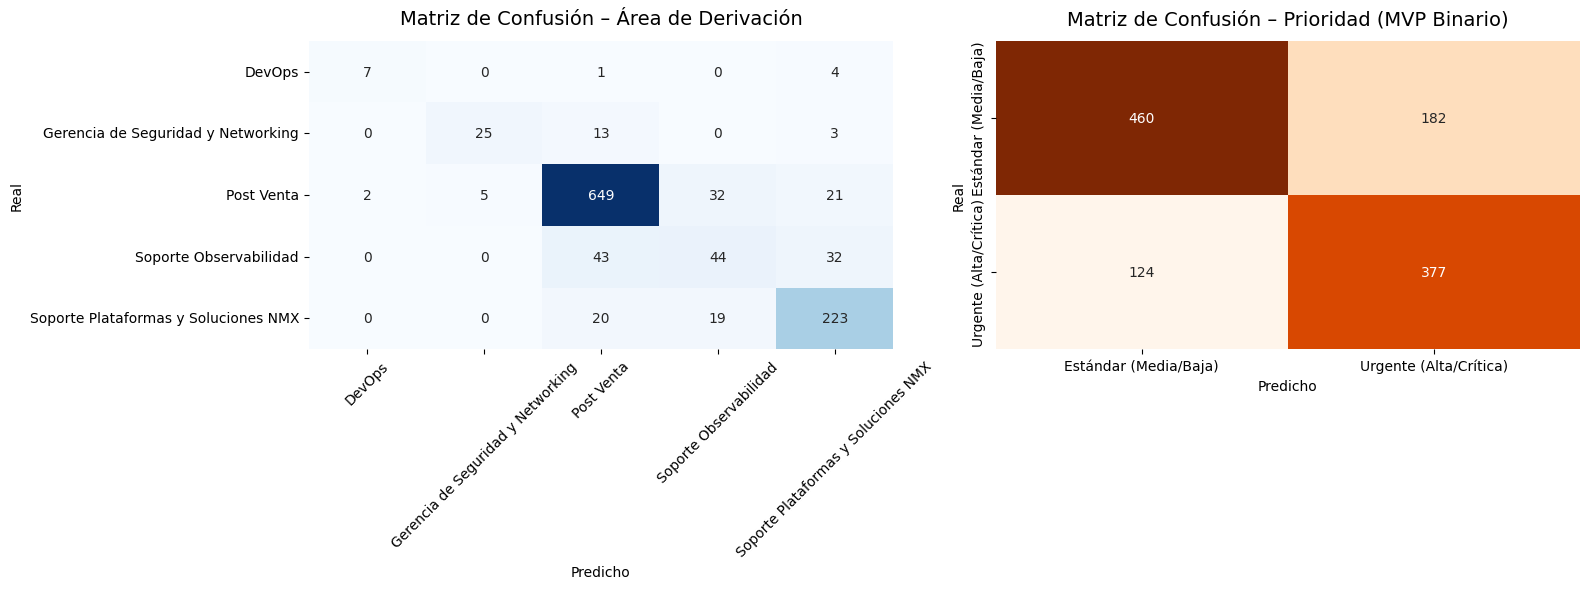

In [ ]:
# ============================================================
# FASE 5: EVALUATION – Matrices de Confusión
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Matriz Área
cm_area = confusion_matrix(y_test[:, 0], y_pred_area)
sns.heatmap(
    cm_area, annot=True, fmt="d", cmap="Blues",
    xticklabels=le_area.classes_,
    yticklabels=le_area.classes_,
    ax=axes[0], cbar=False
)
axes[0].set_title("Matriz de Confusión – Área de Derivación", fontsize=14, pad=12)
axes[0].set_xlabel("Predicho")
axes[0].set_ylabel("Real")
axes[0].tick_params(axis='x', rotation=45)

# Matriz Prioridad (Binaria)
cm_prio = confusion_matrix(y_test[:, 1], y_pred_prio)
sns.heatmap(
    cm_prio, annot=True, fmt="d", cmap="Oranges",
    xticklabels=le_prioridad_bin.classes_,
    yticklabels=le_prioridad_bin.classes_,
    ax=axes[1], cbar=False
)
axes[1].set_title("Matriz de Confusión – Prioridad (MVP Binario)", fontsize=14, pad=12)
axes[1].set_xlabel("Predicho")
axes[1].set_ylabel("Real")

plt.tight_layout()
plt.show()

**CELDA 8.1 – Interpretación de Resultados (Matriz de confusión)**

**Análisis de las Matrices de Confusión:**

Las matrices de confusión confirman que el modelo de Área de derivación alcanza una alta precisión en las clases de mayor volumen, clasificando correctamente la gran mayoría de los tickets de Post Venta (649) y Soporte Plataformas y Soluciones NMX (223); la principal fuente de error se concentra en Soporte Observabilidad, donde 43 casos se confunden con Post Venta y 32 con Plataformas, debido al solapamiento natural del vocabulario técnico de monitoreo e infraestructura entre estas áreas. En cuanto a la Prioridad binaria, el clasificador se comporta de forma robusta, aunque registra 182 falsos positivos (tickets Estándar predichos como Urgentes) y 124 falsos negativos (Urgentes clasificados como Estándar); desde una perspectiva operativa de soporte TI, esta tendencia conservadora a sobreestimar la urgencia resulta preferible, pues es más seguro que el sistema asigne prioritariamente una alta prioridad —corrigible por el técnico con un solo clic— a que subestime un incidente crítico real.

**CELDA 8.2 – FASE 5: EVALUATION – Importancia de Variables**


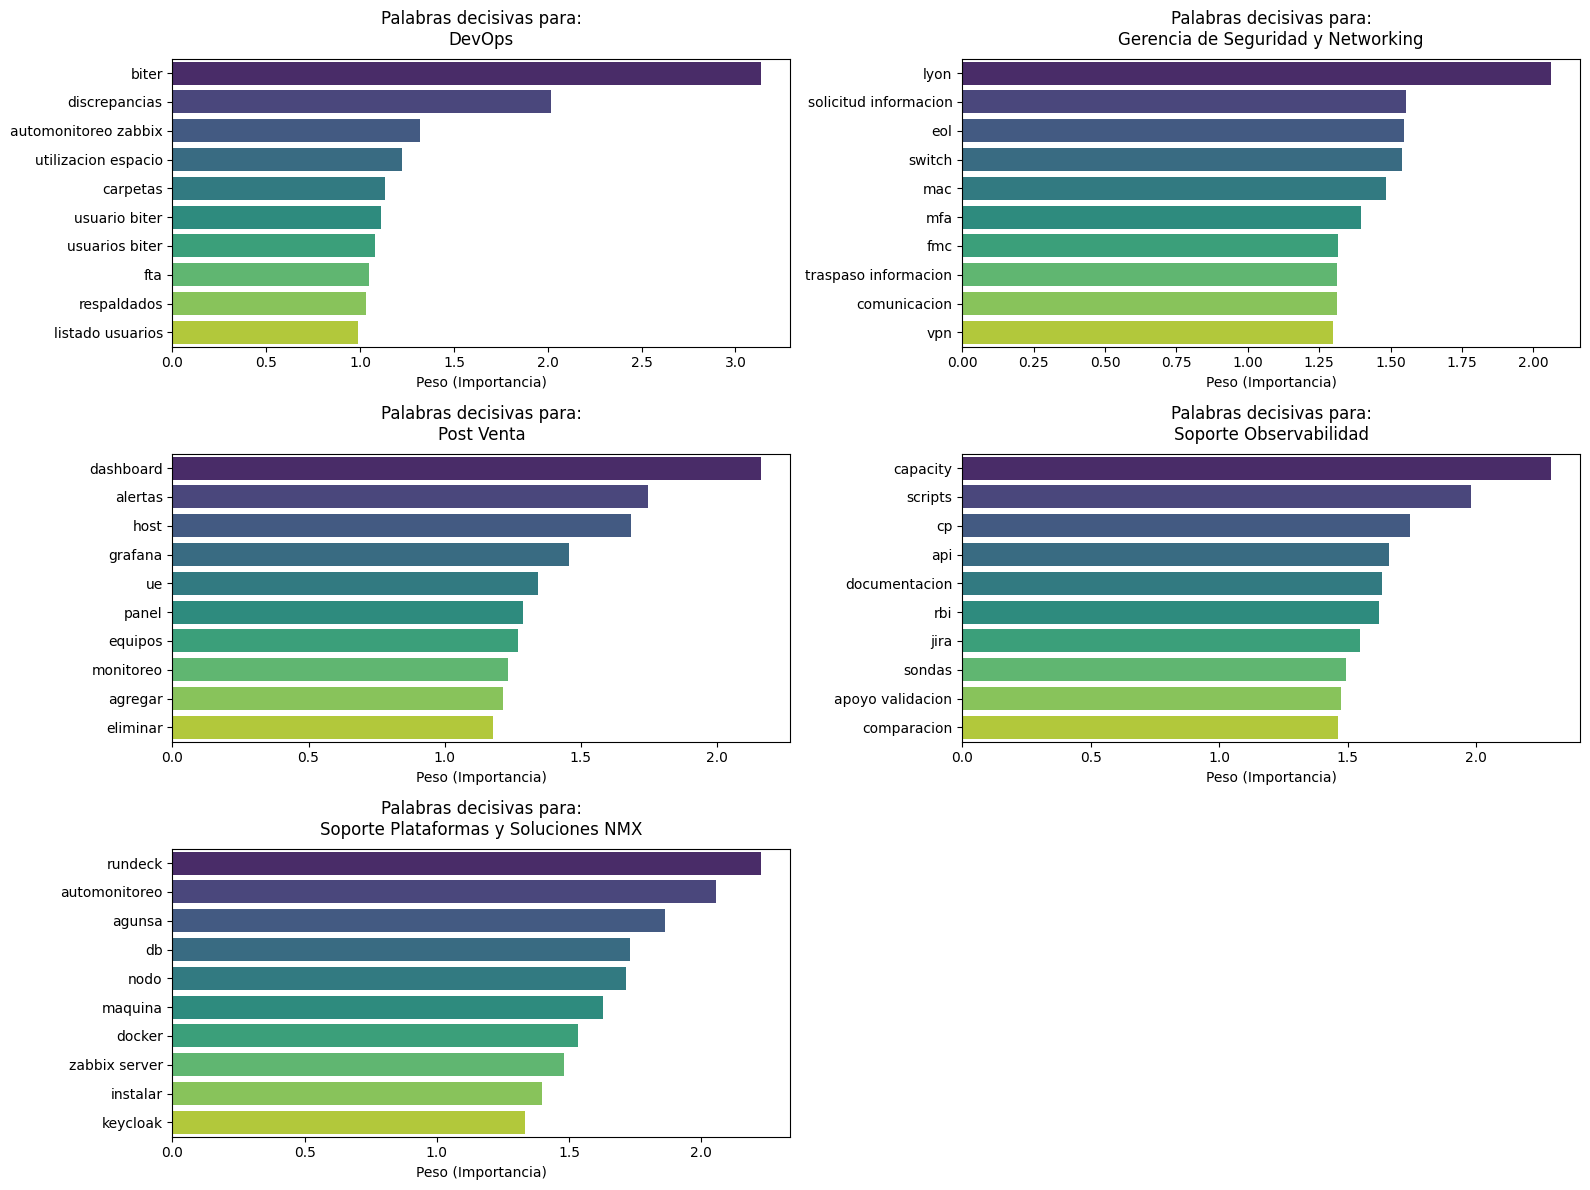

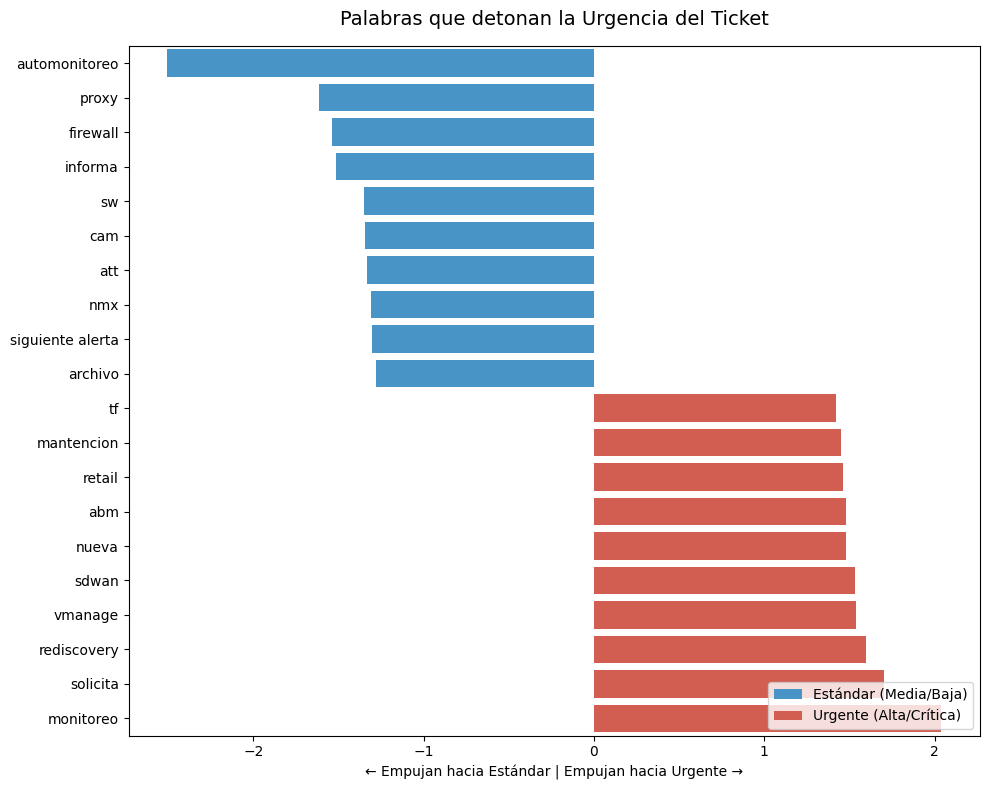

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. Palabras Clave: Modelo de ÁREA DE DERIVACIÓN (LinearSVC)
# ------------------------------------------------------------
tfidf_area = pipeline_area.named_steps['tfidf']
clf_area = pipeline_area.named_steps['clf']
vocab_area = tfidf_area.get_feature_names_out()

# Configuramos una grilla de gráficos (3 filas x 2 columnas para 5 áreas)
fig, axes = plt.subplots(3, 2, figsize=(16, 12))
axes = axes.flatten()

# Iteramos sobre cada área para extraer sus 10 palabras con más peso
for i, area_name in enumerate(le_area.classes_):
    coefs = clf_area.coef_[i]
    top_indices = np.argsort(coefs)[-10:] # Top 10 positivos

    df_top = pd.DataFrame({
        'Palabra': vocab_area[top_indices],
        'Peso': coefs[top_indices]
    }).sort_values(by='Peso', ascending=False)

    sns.barplot(x='Peso', y='Palabra', data=df_top, ax=axes[i], palette='viridis')
    axes[i].set_title(f'Palabras decisivas para:\n{area_name}', fontsize=12, pad=10)
    axes[i].set_xlabel('Peso (Importancia)')
    axes[i].set_ylabel('')

# Ocultar el sexto gráfico sobrante (solo tenemos 5 áreas)
fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Palabras Clave: Modelo de PRIORIDAD (Logística Binaria)
# ------------------------------------------------------------
tfidf_prio = pipeline_prioridad_bin.named_steps['tfidf']
clf_prio = pipeline_prioridad_bin.named_steps['clf']
vocab_prio = tfidf_prio.get_feature_names_out()

# En un modelo binario, hay un solo vector de pesos.
# Los valores negativos empujan a la clase 0 ("Estándar") y los positivos a la clase 1 ("Urgente").
coefs_prio = clf_prio.coef_[0]

# Extraemos las 10 palabras más negativas (Estándar) y las 10 más positivas (Urgente)
top_estandar_idx = np.argsort(coefs_prio)[:10]
top_urgente_idx = np.argsort(coefs_prio)[-10:]

df_prio = pd.DataFrame({
    'Palabra': np.concatenate([vocab_prio[top_estandar_idx], vocab_prio[top_urgente_idx]]),
    'Peso': np.concatenate([coefs_prio[top_estandar_idx], coefs_prio[top_urgente_idx]]),
    'Prioridad': ['Estándar (Media/Baja)'] * 10 + ['Urgente (Alta/Crítica)'] * 10
})

df_prio = df_prio.sort_values(by='Peso', ascending=True)

# Visualización
plt.figure(figsize=(10, 8))
sns.barplot(
    x='Peso',
    y='Palabra',
    hue='Prioridad',
    data=df_prio,
    dodge=False,
    palette={'Estándar (Media/Baja)': '#3498db', 'Urgente (Alta/Crítica)': '#e74c3c'}
)
plt.title('Palabras que detonan la Urgencia del Ticket', fontsize=14, pad=15)
plt.xlabel('← Empujan hacia Estándar | Empujan hacia Urgente →')
plt.ylabel('')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

**CELDA 8.3 – Interpretación de Resultados: Importancia de Variables**

Las visualizaciones de importancia de variables evidencian que el modelo de clasificación de Área de derivación captura de forma efectiva el vocabulario técnico especializado de cada equipo (por ejemplo, términos como “biter” y “zabbix” en DevOps, “switch”, “mfa” y “vpn” en Gerencia de Seguridad y Networking, o “rundeck”, “docker” y “keycloak” en Soporte Plataformas y Soluciones NMX), lo que favorece una discriminación semántica clara y explica el buen desempeño del clasificador; en contraste, el modelo de Prioridad binaria muestra features más contextuales y menos exclusivas, donde palabras asociadas a mantenciones, cambios o nuevas implementaciones empujan hacia la clase Urgente, mientras que términos de monitoreo automático y notificaciones rutinarias orientan hacia Estándar. Cabe destacar que la aparición de “agunsa” (nombre de un cliente) entre las palabras decisivas del área de Soporte Plataformas y Soluciones NMX subraya la necesidad prioritaria de reforzar la etapa de anonimización de datos personales antes del despliegue, en línea con el cumplimiento de la Ley Nº 21.719 exigido para el proyecto Ticki-TI.

**FASE 6: DEPLOYMENT – Exportación e Inferencia para Streamlit**

In [ ]:
import joblib

# 1. Exportación de Artefactos (Guardado físico de los modelos y encoders)
joblib.dump(pipeline_area, "modelo_area.joblib")
joblib.dump(pipeline_prioridad_bin, "modelo_prioridad_binaria.joblib")
joblib.dump(le_area, "le_area.joblib")
joblib.dump(le_prioridad_bin, "le_prioridad_bin.joblib")

print("✅ Artefactos guardados exitosamente (.joblib)")

# 2. Función modular de inferencia (El motor para tu backend web)
def predecir_nuevo_ticket(texto_crudo):
    """
    Recibe el texto extraído por el OCR (o ingresado por el usuario),
    lo limpia y devuelve la clasificación de Área y Prioridad.
    """
    # Se reutiliza la función limpiar_texto que definiste en la Fase 3
    texto_limpio = limpiar_texto(texto_crudo)

    if len(texto_limpio) < 25:
        return {
            "estado": "error",
            "mensaje": "Texto insuficiente para una predicción confiable (mínimo 25 caracteres útiles)."
        }

    # Inferencia de los modelos
    pred_area_num = pipeline_area.predict([texto_limpio])[0]
    pred_prio_num = pipeline_prioridad_bin.predict([texto_limpio])[0]

    # Decodificación de números a texto legible usando los LabelEncoders
    area_final = le_area.inverse_transform([pred_area_num])[0]
    prio_final = le_prioridad_bin.inverse_transform([pred_prio_num])[0]

    # Retorno en formato estructurado (ideal para APIs o diccionarios en Streamlit)
    return {
        "estado": "exito",
        "texto_procesado_ia": texto_limpio,
        "prediccion": {
            "area_derivacion": area_final,
            "prioridad_operativa": prio_final
        }
    }

✅ Artefactos guardados exitosamente (.joblib)

--- Simulacro de Inferencia en Producción ---
Texto original: Estimados, favor revisar con suma urgencia el nodo principal, tenemos una caída masiva y el firewall no responde. Atte, Jorge.
Texto que analizó la IA (sin ruido): estimados favor revisar con suma urgencia el nodo principal tenemos una caída masiva y el firewall no responde atte jorge
➜ Área sugerida:      Gerencia de Seguridad y Networking
➜ Prioridad sugerida: Estándar (Media/Baja)
